## Loading Libraries


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer

## Load Rwanda Landslide Dataset

In [4]:
df = pd.read_csv("Rwanda_Landslide_Dataset-selected-columns.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Display First Five Rows

In [5]:
df.head()

,latitude,longitude,elevation_m,slope_degree,aspect,soil_type,rock_type,rainfall_mm_last_24h,rainfall_mm_last_7d,temperature_c,...,distance_to_river_m,distance_to_road_m,population_density,previous_landslides_count,soil_moisture,earthquake_magnitude_recent,rainfall_anomaly_index,timestamp,region,landslide_occurred
0,-2.384375,30.129272,1512.004340,45.540729,S,Clay,Igneous,1.645904,7.450369,14.902675,...,923.814279,185.785100,668.548348,0.0,0.544169,2.127626,0.901540,2015-12-01 20:00:00,Southern,1
1,-2.422505,29.719482,1342.640530,36.265280,N,Sandy,Igneous,7.293822,57.900464,17.602552,...,254.493320,895.034058,1620.150165,0.0,0.327317,4.420502,-0.000289,2017-02-18 22:00:00,Western,0
2,-2.519032,29.606253,1838.279921,58.647585,W,Peat,Metamorphic,24.019140,203.296509,20.628320,...,1140.521824,736.717148,516.258433,0.0,0.431795,5.074582,-0.754806,2016-10-02 19:00:00,Northern,1
3,-2.352397,30.879907,1756.260990,55.748613,N,Silt,Metamorphic,10.871508,79.644082,20.776244,...,764.908234,292.353973,1098.141045,0.0,0.391022,5.203580,0.206497,2016-02-01 04:00:00,Kigali,1
4,-1.923006,29.603568,1990.654662,25.576538,W,Loam,Metamorphic,24.045195,165.934935,20.098768,...,48.417211,259.867005,622.495718,0.0,0.455890,3.253148,0.470901,2016-09-07 13:00:00,Kigali,1


## Dataset Information

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37322 entries, 0 to 37321
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   latitude                     35342 non-null  float64
 1   longitude                    35369 non-null  float64
 2   elevation_m                  35565 non-null  float64
 3   slope_degree                 35421 non-null  float64
 4   aspect                       35284 non-null  str    
 5   soil_type                    35354 non-null  str    
 6   rock_type                    35612 non-null  str    
 7   rainfall_mm_last_24h         35379 non-null  float64
 8   rainfall_mm_last_7d          35571 non-null  float64
 9   temperature_c                35245 non-null  float64
 10  vegetation_index_ndvi        35474 non-null  float64
 11  land_use                     35611 non-null  str    
 12  distance_to_river_m          35436 non-null  float64
 13  distance_to_road_m         

## Dataset Shape

In [7]:
rows, columns = df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 37322
Number of columns: 22


## Summary Statistics

In [8]:
df.describe()

,latitude,longitude,elevation_m,slope_degree,rainfall_mm_last_24h,rainfall_mm_last_7d,temperature_c,vegetation_index_ndvi,distance_to_river_m,distance_to_road_m,population_density,previous_landslides_count,soil_moisture,earthquake_magnitude_recent,rainfall_anomaly_index,landslide_occurred
count,35342.000000,35369.000000,35565.000000,35421.000000,35379.000000,35571.000000,35245.000000,35474.000000,35436.000000,35557.000000,35547.000000,35513.000000,35400.000000,35392.000000,35351.000000,37322.000000
mean,-1.959462,29.831149,1640.309834,39.843146,23.184556,156.503136,19.985220,0.455782,1021.114230,488.664885,1007.185918,0.297356,0.388689,3.965722,0.004828,0.500000
std,0.545836,0.613619,299.948280,17.121018,16.884169,131.675162,3.035812,0.230575,1001.749210,488.363530,709.734778,0.547525,0.155770,1.158759,0.984911,0.500007
min,-2.899978,28.800012,900.000000,0.007801,0.117450,0.761930,10.000000,0.100032,0.008493,0.001114,50.000000,0.000000,0.050027,2.000570,-4.207929,0.000000
25%,-2.431144,29.290499,1435.227324,27.779282,11.180946,66.800669,17.911968,0.251056,284.269535,138.896487,497.535780,0.000000,0.269840,2.985161,-0.666346,0.000000
50%,-1.961348,29.834274,1638.244476,45.682074,19.395002,121.246920,20.001604,0.435591,724.945013,338.027071,852.036790,0.000000,0.421614,3.944529,0.010701,0.500000
75%,-1.489744,30.367063,1846.482126,54.011164,30.747611,205.722752,22.016558,0.647852,1424.410991,674.605518,1338.634262,1.000000,0.522603,4.961154,0.672328,1.000000
max,-1.000143,30.899792,2718.350003,59.992506,131.114853,1251.386613,31.889486,0.899928,8000.000000,4763.744922,6271.099238,4.000000,0.599988,5.999936,4.185208,1.000000


## Number of Missing Values

In [9]:
missing_values = df.isnull().sum()

print(missing_values)

latitude                       1980
longitude                      1953
elevation_m                    1757
slope_degree                   1901
aspect                         2038
soil_type                      1968
rock_type                      1710
rainfall_mm_last_24h           1943
rainfall_mm_last_7d            1751
temperature_c                  2077
vegetation_index_ndvi          1848
land_use                       1711
distance_to_river_m            1886
distance_to_road_m             1765
population_density             1775
previous_landslides_count      1809
soil_moisture                  1922
earthquake_magnitude_recent    1930
rainfall_anomaly_index         1971
timestamp                      1985
region                         1957
landslide_occurred                0
dtype: int64


## Number of Missing Values in %

In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

latitude                       5.305182
longitude                      5.232839
elevation_m                    4.707679
slope_degree                   5.093511
aspect                         5.460586
soil_type                      5.273029
rock_type                      4.581748
rainfall_mm_last_24h           5.206045
rainfall_mm_last_7d            4.691603
temperature_c                  5.565082
vegetation_index_ndvi          4.951503
land_use                       4.584427
distance_to_river_m            5.053320
distance_to_road_m             4.729114
population_density             4.755908
previous_landslides_count      4.847007
soil_moisture                  5.149778
earthquake_magnitude_recent    5.171213
rainfall_anomaly_index         5.281067
timestamp                      5.318579
region                         5.243556
landslide_occurred             0.000000
dtype: float64


## Missing Values Heatmap

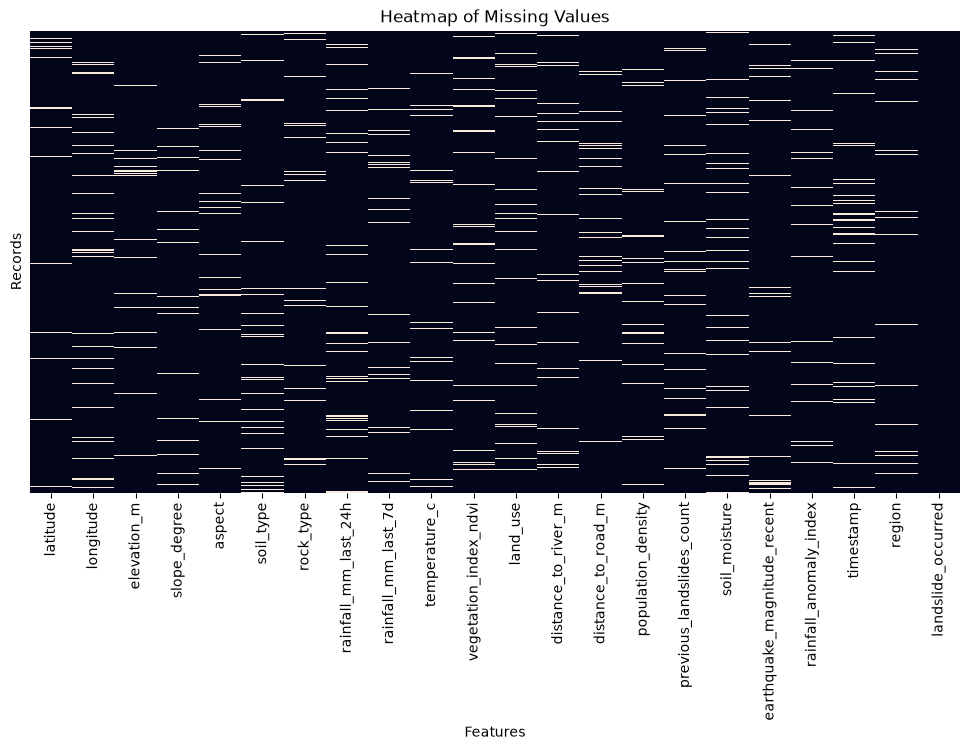

In [11]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), 
            cbar=False, 
            yticklabels=False)

plt.title("Heatmap of Missing Values")
plt.xlabel("Features")
plt.ylabel("Records")

plt.show()

## Check Landslide Target Variable

In [12]:
print(df["landslide_occurred"].value_counts())
print(df["landslide_occurred"].value_counts(normalize=True) * 100)

landslide_occurred
1    18661
0    18661
Name: count, dtype: int64
landslide_occurred
1    50.0
0    50.0
Name: proportion, dtype: float64


## Landslide Occurrence Distribution

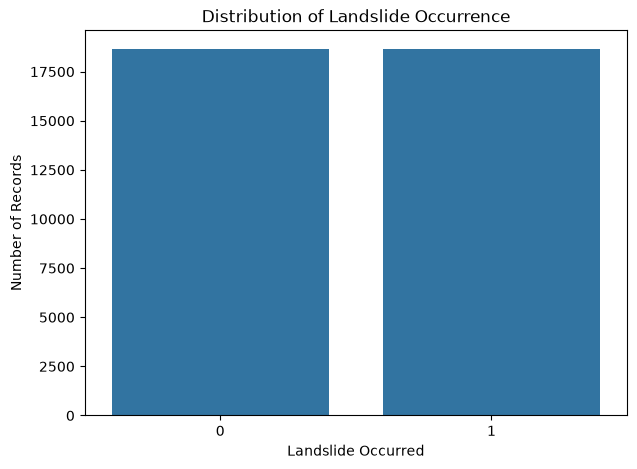

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(x="landslide_occurred", data=df)

plt.title("Distribution of Landslide Occurrence")
plt.xlabel("Landslide Occurred")
plt.ylabel("Number of Records")

plt.show()

## Correlation Heatmap

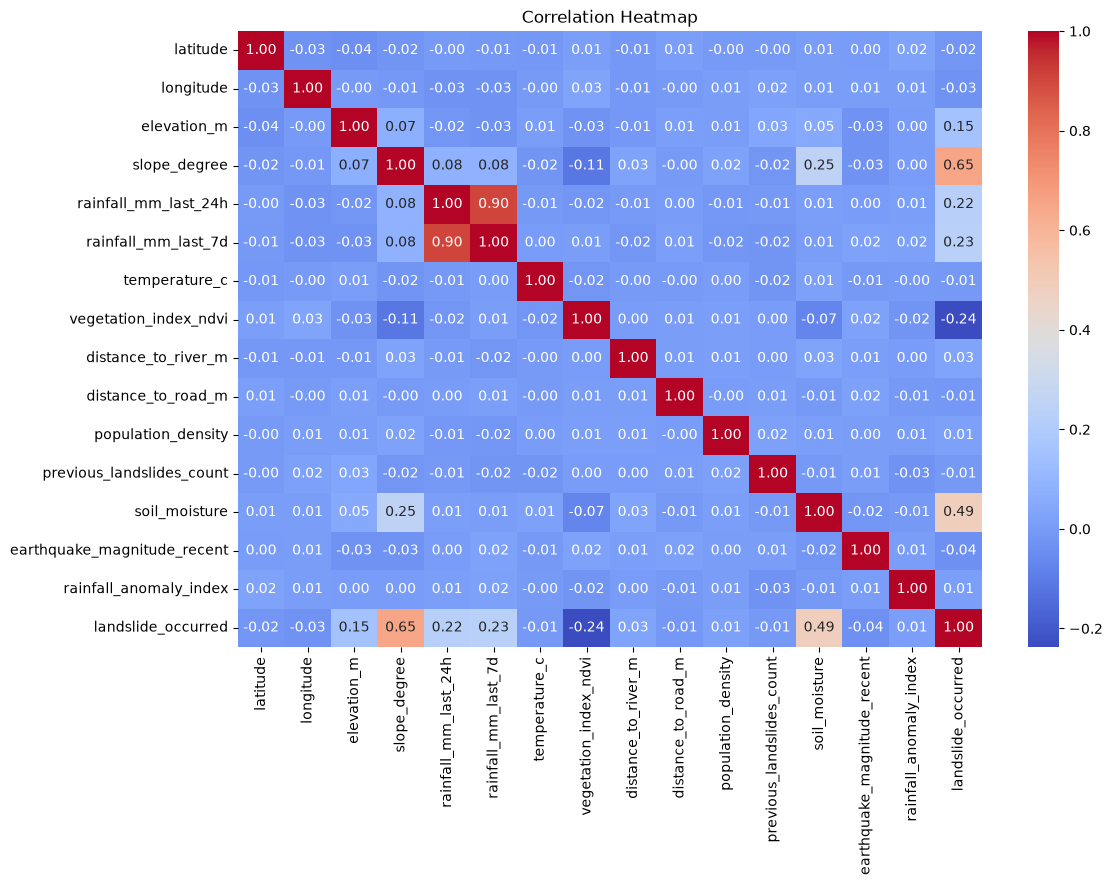

landslide_occurred             1.000000
slope_degree                   0.654067
soil_moisture                  0.485413
rainfall_mm_last_7d            0.228408
rainfall_mm_last_24h           0.223401
elevation_m                    0.150567
distance_to_river_m            0.029087
population_density             0.014093
rainfall_anomaly_index         0.013812
previous_landslides_count     -0.008781
temperature_c                 -0.009163
distance_to_road_m            -0.014820
latitude                      -0.017952
longitude                     -0.031255
earthquake_magnitude_recent   -0.035242
vegetation_index_ndvi         -0.237432
Name: landslide_occurred, dtype: float64


In [14]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

target_correlation = numeric_df.corr()["landslide_occurred"].sort_values(
    ascending=False
)

print(target_correlation)

## Identify Feature Types

In [31]:
target = "landslide_occurred"

num_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_features = df.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Remove target from feature lists
if target in num_features:
    num_features.remove(target)

if target in cat_features:
    cat_features.remove(target)

print("Numeric features:")
print(num_features)

print("\nCategorical features:")
print(cat_features)

Numeric features:
['latitude', 'longitude', 'elevation_m', 'slope_degree', 'rainfall_mm_last_24h', 'rainfall_mm_last_7d', 'temperature_c', 'vegetation_index_ndvi', 'distance_to_river_m', 'distance_to_road_m', 'population_density', 'previous_landslides_count', 'soil_moisture', 'earthquake_magnitude_recent', 'rainfall_anomaly_index']

Categorical features:
['aspect', 'soil_type', 'rock_type', 'land_use', 'timestamp', 'region']


## Mean Imputation for Numeric Features

In [16]:
for column in num_features:
    df[column] = df[column].fillna(df[column].mean())

print("Numeric missing values filled using mean.")
print(df[num_features].isnull().sum())

Numeric missing values filled using mean.
latitude                       0
longitude                      0
elevation_m                    0
slope_degree                   0
rainfall_mm_last_24h           0
rainfall_mm_last_7d            0
temperature_c                  0
vegetation_index_ndvi          0
distance_to_river_m            0
distance_to_road_m             0
population_density             0
previous_landslides_count      0
soil_moisture                  0
earthquake_magnitude_recent    0
rainfall_anomaly_index         0
dtype: int64


## Mode Imputation for Categorical Features

In [17]:
for column in cat_features:
    df[column] = df[column].fillna(df[column].mode()[0])

print("Categorical missing values filled using mode.")
print(df[cat_features].isnull().sum())

Categorical missing values filled using mode.
aspect       0
soil_type    0
rock_type    0
land_use     0
timestamp    0
region       0
dtype: int64


## Detect Outliers Using IQR Method

In [18]:
outlier_counts = {}

for column in num_features:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    outlier_counts[column] = len(outliers)

print("Outliers per numerical feature:")

for column, count in outlier_counts.items():
    print(column, ":", count)

Outliers per numerical feature:
latitude : 0
longitude : 0
elevation_m : 146
slope_degree : 0
rainfall_mm_last_24h : 1642
rainfall_mm_last_7d : 1856
temperature_c : 352
vegetation_index_ndvi : 0
distance_to_river_m : 1885
distance_to_road_m : 2084
population_density : 1385
previous_landslides_count : 9133
soil_moisture : 0
earthquake_magnitude_recent : 0
rainfall_anomaly_index : 279


## Total Number of Outliers

In [19]:
total_outliers = sum(outlier_counts.values())

print("Total number of outliers:", total_outliers)

Total number of outliers: 18762


## Unique rows containing outliers

In [20]:
outlier_rows = pd.Series(False, index=df.index)

for column in num_features:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_rows |= (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

print("Unique rows containing outliers:", outlier_rows.sum())

Unique rows containing outliers: 14972


## Boxplots for Numerical Features

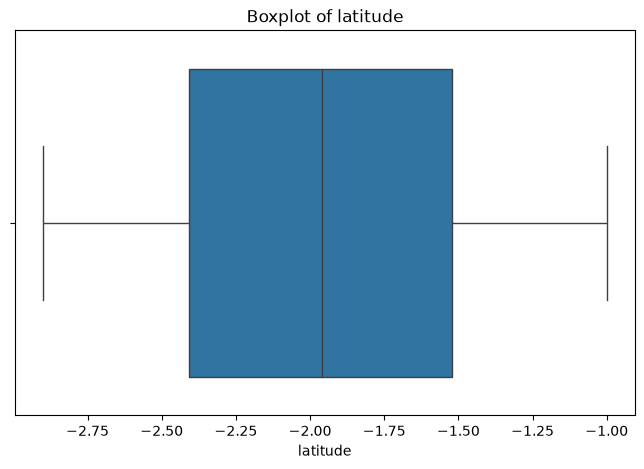

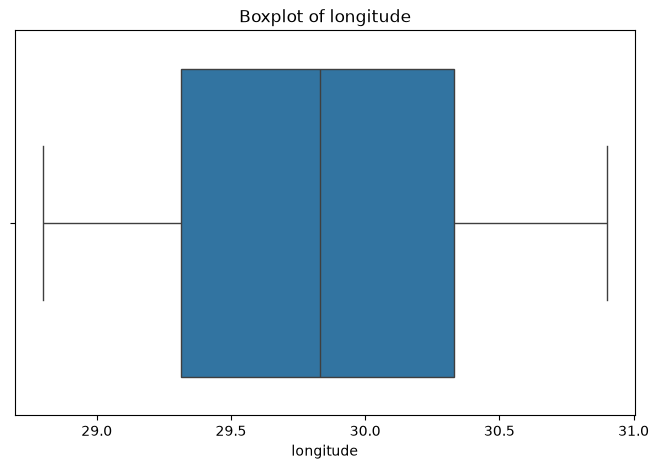

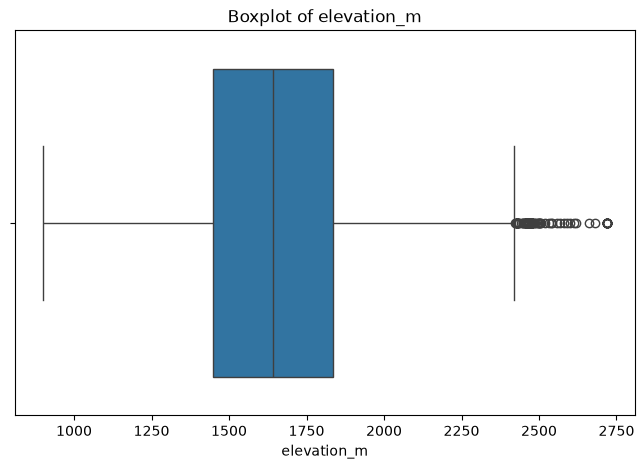

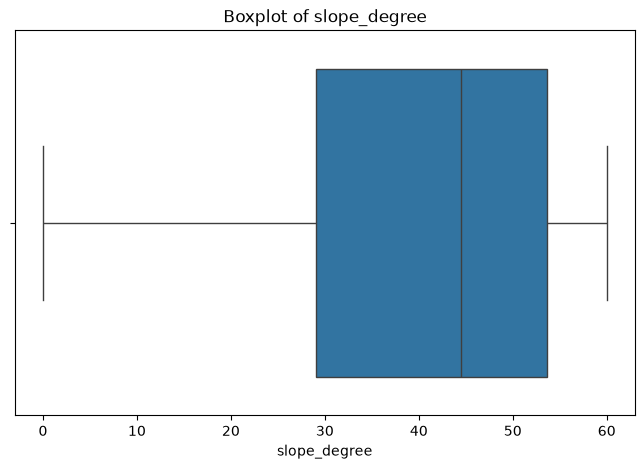

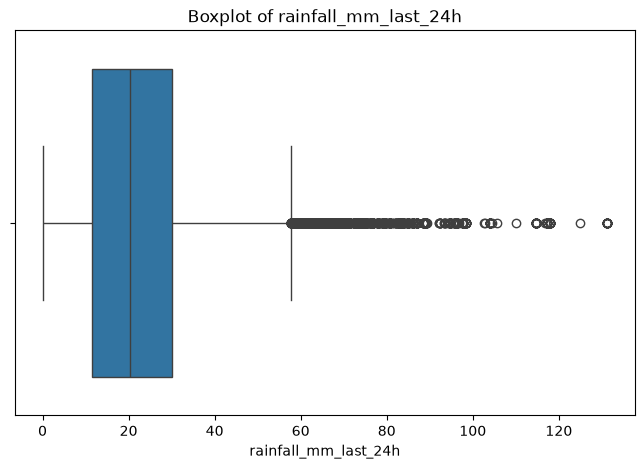

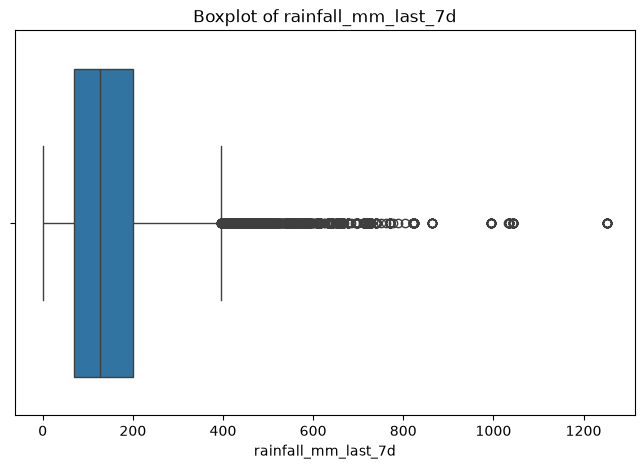

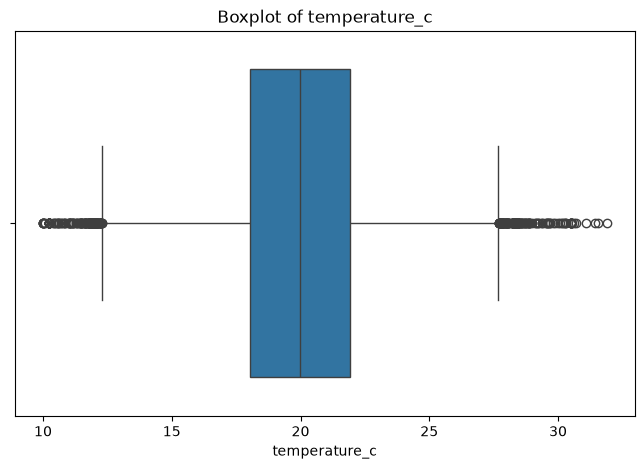

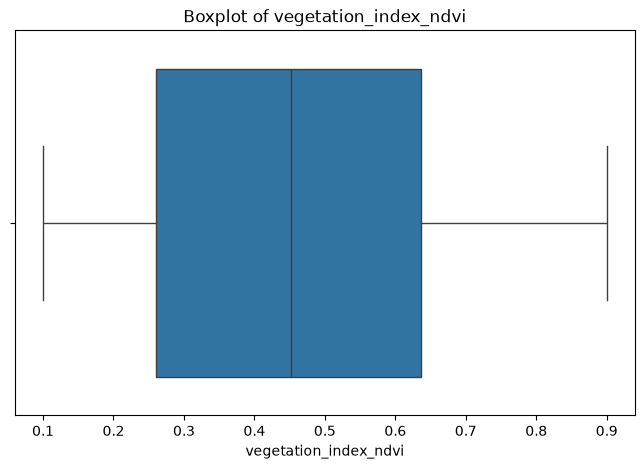

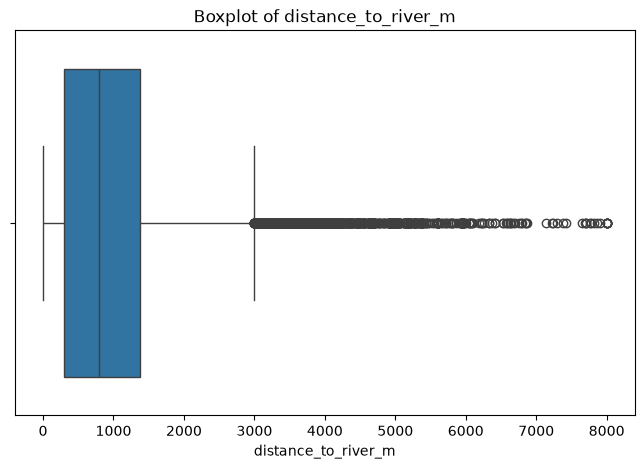

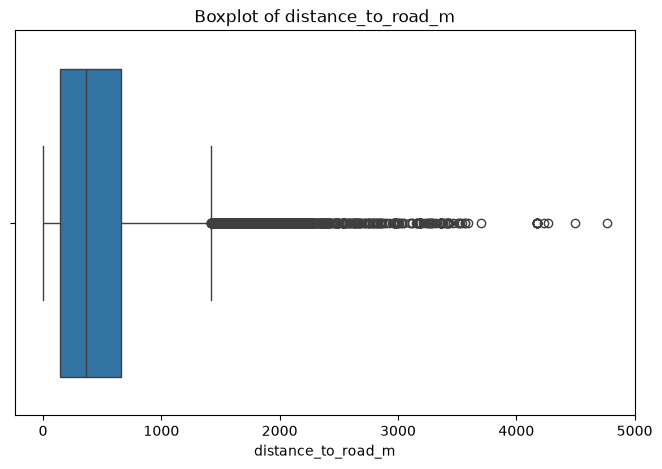

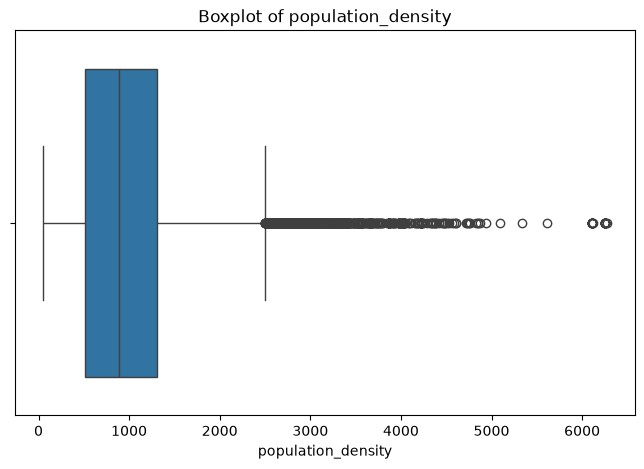

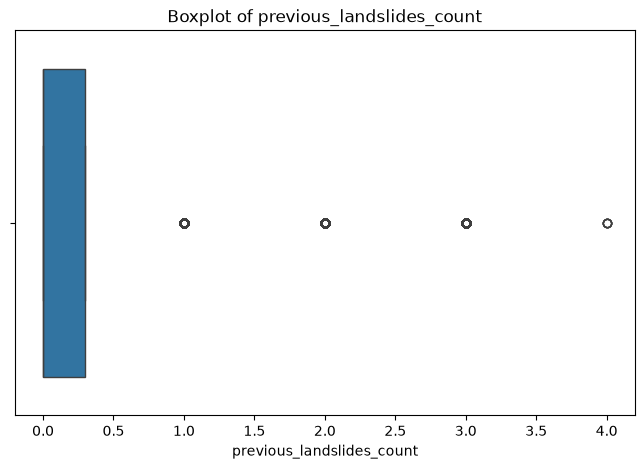

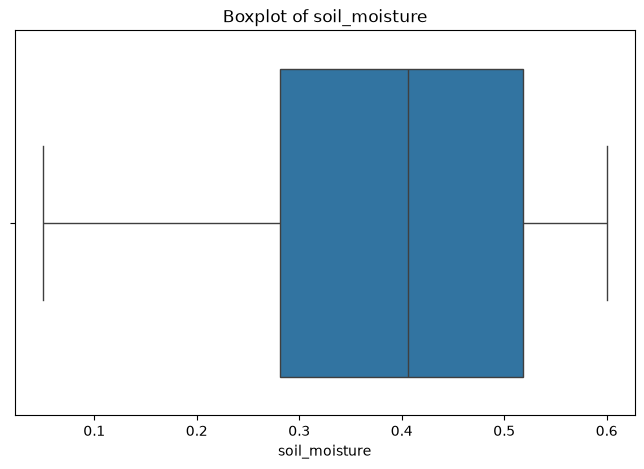

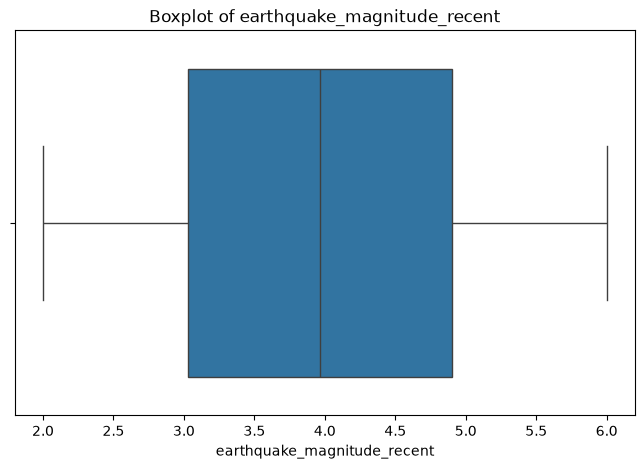

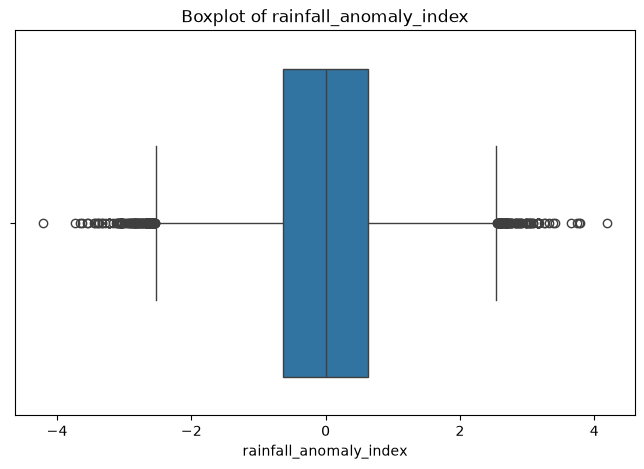

In [21]:
for column in num_features:
    
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(x=df[column])
    
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    
    plt.show()

Explanation of Environmental Outliers

Yes: Outliers may be removed if they are caused by measurement errors, data-entry errors, or faulty sensors because they can distort statistical analysis and machine-learning models.

No: Outliers should not automatically be removed because extreme environmental conditions may represent real events. For example, unusually high rainfall could be a genuine extreme weather event associated with landslides.

## Separate Features and Target

In [22]:
X = df.drop("landslide_occurred", axis=1)

y = df["landslide_occurred"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   latitude  longitude  elevation_m  slope_degree aspect soil_type  \
0 -2.384375  30.129272  1512.004340     45.540729      S      Clay   
1 -2.422505  29.719482  1342.640530     36.265280      N     Sandy   
2 -2.519032  29.606253  1838.279921     58.647585      W      Peat   
3 -2.352397  30.879907  1756.260990     55.748613      N      Silt   
4 -1.923006  29.603568  1990.654662     25.576538      W      Loam   

     rock_type  rainfall_mm_last_24h  rainfall_mm_last_7d  temperature_c  ...  \
0      Igneous              1.645904             7.450369      14.902675  ...   
1      Igneous              7.293822            57.900464      17.602552  ...   
2  Metamorphic             24.019140           203.296509      20.628320  ...   
3  Metamorphic             10.871508            79.644082      20.776244  ...   
4  Metamorphic             24.045195           165.934935      20.098768  ...   

      land_use distance_to_river_m  distance_to_road_m  population_density  \
0   

## Train-Test Split Using Stratification

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 29857
Testing samples: 7465


## Create ColumnTransformer

In [25]:
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            num_features
        ),
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            cat_features
        )
    ]
)

## Fit Transform Training Data

In [26]:
X_train_transformed = preprocessor.fit_transform(X_train)

print("Training data transformed successfully.")
print("Training shape:", X_train_transformed.shape)

Training data transformed successfully.
Training shape: (29857, 21)


## Transform Testing Data

In [27]:
X_test_transformed = preprocessor.transform(X_test)

print("Testing data transformed successfully.")
print("Testing shape:", X_test_transformed.shape)

Testing data transformed successfully.
Testing shape: (7465, 21)


##  Check Preprocessed Data

In [28]:
print("X_train transformed:")
print(X_train_transformed)

print("\nX_test transformed:")
print(X_test_transformed)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

X_train transformed:
[[-1.15934004e+00 -1.33367707e+00 -2.01595698e+00 ...  3.00000000e+00
   2.40000000e+01  4.00000000e+00]
 [-9.59676591e-01  2.41537810e-01 -2.28971923e+00 ...  2.00000000e+00
   1.25100000e+04  2.00000000e+00]
 [-4.52753606e-01 -4.42939148e-01  1.23208738e+00 ...  0.00000000e+00
   7.19200000e+03  1.00000000e+00]
 ...
 [ 2.63364432e-03 -1.79837160e-03 -1.93263183e-01 ...  3.00000000e+00
   4.29800000e+03  0.00000000e+00]
 [ 1.27097247e+00  1.12109020e+00 -3.25418737e-01 ...  3.00000000e+00
   8.51700000e+03  4.00000000e+00]
 [ 2.63364432e-03 -1.23207021e+00 -1.40379920e+00 ...  2.00000000e+00
   6.64800000e+03  3.00000000e+00]]

X_test transformed:
[[-1.12190991e+00  1.22655291e+00  6.23929455e-01 ...  3.00000000e+00
   1.04500000e+03  1.00000000e+00]
 [-4.76498732e-01  1.76127391e-01  2.29224389e+00 ...  0.00000000e+00
   4.47800000e+03  4.00000000e+00]
 [ 2.42998989e-01  4.09265194e-01 -2.77396115e-01 ...  2.00000000e+00
  -1.00000000e+00  1.00000000e+00]
 ...
 [

## Save Cleaned Dataset

In [34]:
df.to_csv(
    "Rwanda_Landslide_Cleaned2.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

PermissionError: [Errno 13] Permission denied: 'Rwanda_Landslide_Cleaned2.csv'